# GDFM Network Setup and Backbone Walkthrough

This notebook is about **model setup**, not training, sampling, or GDFM loss logic.

It is meant to answer four concrete questions:
- What does the canonical `gdfm.build_network(...)` API expect?
- Which concrete backbone do we get when we ask for `"mlp"`, `"unet"`, or `"jit"`?
- How large are these networks in parameter count, and where do those parameters live?
- Do the forward contracts actually work on vectors and images, with the expected shape changes?

What this notebook deliberately does **not** try to show:
- sample quality
- memorization behavior
- prediction-space or loss-space effects
- training dynamics

The outputs below are from **untrained** networks. The point is structural sanity checking.

## Roadmap

1. Build canonical nested configs for the three backbones.
2. Show how the factory normalizes those configs, including legacy aliases.
3. Instantiate the MLP, Bonnaire-style UNet, and vendored JiT wrapper.
4. Inspect parameter counts, grouped parameter budgets, and layer-wise shape traces.
5. Run one real forward pass for vectors, grayscale images, and RGB images.

In [11]:
import os

os.environ.setdefault("MPLCONFIGDIR", "/tmp/mpl")

from pathlib import Path

import sys

WORKDIR = Path.cwd()
REPO_ROOT = WORKDIR if (WORKDIR / "gdfm").exists() else WORKDIR.parent
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import display
from ml_collections import ConfigDict

from gdfm import build_network
from gdfm.model_setup import _normalize_network_config
from gdfm.notebook_utils import (
    backbone_row,
    make_grayscale_demo,
    make_rgb_demo,
    make_time_batch,
    make_vector_demo,
    parameter_groups,
    parameter_overview,
    parameter_table,
    plot_image_io,
    plot_vector_io,
    run_with_trace,
    set_seed,
    stats_table,
)

set_seed(7)
torch.set_grad_enabled(False)
pd.set_option("display.max_rows", 200)
pd.set_option("display.max_colwidth", 120)
plt.rcParams["figure.facecolor"] = "white"

DEVICE = torch.device("cpu")
print("Using device:", DEVICE)
print("Notebook file:", Path("gdfm/model_setup_networks_walkthrough.ipynb").resolve())

Using device: cpu
Notebook file: /Users/mohammadaljaff/Desktop/PhD/projects/mem_param/mem_par/gdfm/gdfm/model_setup_networks_walkthrough.ipynb


## 1. Canonical model-setup surface

The long-term public API is the nested config surface:
- `cfg.network.arch`
- `cfg.network.*`
- `cfg.data.*`

We keep compatibility aliases during transition, but the notebook starts from the canonical nested shape.

In [12]:
def make_mlp_config():
    cfg = ConfigDict()
    cfg.network = ConfigDict()
    cfg.network.arch = "mlp"
    cfg.network.hidden_dim = 128
    cfg.network.n_layers = 3
    cfg.network.time_emb_dim = 64

    cfg.data = ConfigDict()
    cfg.data.data_dim = 32
    return cfg


def make_unet_config():
    cfg = ConfigDict()
    cfg.network = ConfigDict()
    cfg.network.arch = "unet"
    cfg.network.base_channels = 64
    cfg.network.channel_mult = (1, 2, 4, 4)
    cfg.network.attn_resolutions = (8,)
    cfg.network.num_res_blocks = 2
    cfg.network.dropout = 0.0
    cfg.network.time_emb_dim = 256

    cfg.data = ConfigDict()
    cfg.data.image_size = 32
    cfg.data.image_channels = 1
    return cfg


def make_jit_config():
    cfg = ConfigDict()
    cfg.network = ConfigDict()
    cfg.network.arch = "jit"
    cfg.network.patch_size = 16
    cfg.network.hidden_dim = 768
    cfg.network.depth = 12
    cfg.network.heads = 12
    cfg.network.bottleneck_dim = 128
    cfg.network.proj_dropout = 0.0
    cfg.network.attn_dropout = 0.0
    cfg.network.in_context_len = 32
    cfg.network.in_context_start = 4

    cfg.data = ConfigDict()
    cfg.data.image_size = 64
    cfg.data.image_channels = 3
    return cfg


mlp_cfg = make_mlp_config()
unet_cfg = make_unet_config()
jit_cfg = make_jit_config()

canonical_cfgs = {
    "mlp": mlp_cfg,
    "unet": unet_cfg,
    "jit": jit_cfg,
}

legacy_unet_cfg = {
    "network": "unet",
    "model": {
        "in_channels": 1,
        "base_channels": 64,
        "channel_mults": [1, 2, 4, 4],
        "attention_resolutions": [8],
        "num_res_blocks": 2,
        "dropout": 0.0,
        "time_embed_dim": 256,
    },
    "data": {
        "resolution": 32,
    },
}

legacy_jit_cfg = {
    "network": "jit",
    "model": {
        "in_channels": 3,
        "patch_size": 16,
        "hidden_dim": 768,
        "depth": 12,
        "num_heads": 12,
        "bottleneck_dim": 128,
        "dropout": 0.0,
    },
    "data": {
        "resolution": 64,
    },
}

In [13]:
normalized_specs = pd.DataFrame(
    {
        name: pd.Series(_normalize_network_config(cfg))
        for name, cfg in canonical_cfgs.items()
    }
).T

print("Canonical specs after normalization:")
display(normalized_specs)

alias_translation = pd.DataFrame(
    {
        "canonical_unet": pd.Series(_normalize_network_config(unet_cfg)),
        "legacy_unet_aliases": pd.Series(_normalize_network_config(legacy_unet_cfg)),
        "canonical_jit": pd.Series(_normalize_network_config(jit_cfg)),
        "legacy_jit_aliases": pd.Series(_normalize_network_config(legacy_jit_cfg)),
    }
).fillna("")

print("The factory collapses legacy aliases onto the same public spec:")
display(alias_translation)

Canonical specs after normalization:


,arch,attn_dropout,attn_resolutions,base_channels,bottleneck_dim,channel_mult,data_dim,depth,dropout,heads,hidden_dim,image_channels,image_size,in_context_len,in_context_start,n_layers,num_res_blocks,patch_size,proj_dropout,time_emb_dim
mlp,mlp,NaN,NaN,NaN,NaN,NaN,32,NaN,NaN,NaN,128,NaN,NaN,NaN,NaN,3,NaN,NaN,NaN,64
unet,unet,NaN,"(8,)",64,NaN,"(1, 2, 4, 4)",NaN,NaN,0.0,NaN,NaN,1,32,NaN,NaN,NaN,2,NaN,NaN,256
jit,jit,0.0,NaN,NaN,128,NaN,NaN,12,NaN,12,768,3,64,32,4,NaN,NaN,16,0.0,NaN


The factory collapses legacy aliases onto the same public spec:


,canonical_unet,legacy_unet_aliases,canonical_jit,legacy_jit_aliases
arch,unet,unet,jit,jit
attn_dropout,,,0.0,0.0
attn_resolutions,"(8,)","(8,)",,
base_channels,64,64,,
bottleneck_dim,,,128,128
channel_mult,"(1, 2, 4, 4)","(1, 2, 4, 4)",,
depth,,,12,12
dropout,0.0,0.0,,
heads,,,12,12
hidden_dim,,,768,768


## 2. Instantiate the three backbones

This is the first sanity check: if we ask for a backbone, do we get the intended wrapper, and what concrete implementation does it contain internally?

In [14]:
models = {name: build_network(cfg).to(DEVICE) for name, cfg in canonical_cfgs.items()}

inputs = {
    "mlp": (
        make_vector_demo(mlp_cfg.data.data_dim, batch_size=1).to(DEVICE),
        make_time_batch(1, value=0.35).to(DEVICE),
    ),
    "unet": (
        make_grayscale_demo(unet_cfg.data.image_size, batch_size=1).to(DEVICE),
        make_time_batch(1, value=0.35).to(DEVICE),
    ),
    "jit": (
        make_rgb_demo(jit_cfg.data.image_size, batch_size=1).to(DEVICE),
        make_time_batch(1, value=0.35).to(DEVICE),
    ),
}

outputs = {}
rows = []
for name, model in models.items():
    z, t = inputs[name]
    y = model(z, t)
    outputs[name] = y

    inner = getattr(model, "model", None)
    rows.append(
        {
            "backbone": name,
            "wrapper_class": model.__class__.__name__,
            "wrapper_module": model.__class__.__module__,
            "inner_class": inner.__class__.__name__ if inner is not None else "-",
            "inner_module": inner.__class__.__module__ if inner is not None else "-",
            "input_shape": tuple(z.shape),
            "output_shape": tuple(y.shape),
        }
    )

factory_table = pd.DataFrame(rows)
display(factory_table)

,backbone,wrapper_class,wrapper_module,inner_class,inner_module,input_shape,output_shape
0,mlp,TimeCondMLP,gdfm.networks.mlp,-,-,"(1, 32)","(1, 32)"
1,unet,BonnaireUNet,gdfm.networks.unet,SmallUNet,experiments.natural_images.common.networks.unet,"(1, 1, 32, 32)","(1, 1, 32, 32)"
2,jit,JiT,gdfm.networks.jit,JiT,model_jit,"(1, 3, 64, 64)","(1, 3, 64, 64)"


## 3. MLP deep dive

The MLP is the cleanest backbone to inspect because it acts directly on flat vectors.

Here we show:
- the concrete module structure
- the total and grouped parameter counts
- the exact sequence of learnable layers hit in one forward pass
- a structured vector input and its output

TimeCondMLP(
  (time_mlp): TimeEmbeddingMLP(
    (net): Sequential(
      (0): Linear(in_features=64, out_features=64, bias=True)
      (1): SiLU()
      (2): Linear(in_features=64, out_features=64, bias=True)
    )
  )
  (net): Sequential(
    (0): Linear(in_features=96, out_features=128, bias=True)
    (1): SiLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): SiLU()
    (4): Linear(in_features=128, out_features=128, bias=True)
    (5): SiLU()
    (6): Linear(in_features=128, out_features=32, bias=True)
  )
)


,metric,count,pretty
0,total_params,57888,57.89K
1,trainable_params,57888,57.89K
2,frozen_params,0,0


,group,params,pretty
0,net,49568,49.57K
1,time_mlp,8320,8.32K


,name,shape,params,pretty,trainable
0,net.2.weight,"(128, 128)",16384,16.38K,True
1,net.4.weight,"(128, 128)",16384,16.38K,True
2,net.0.weight,"(128, 96)",12288,12.29K,True
3,time_mlp.net.0.weight,"(64, 64)",4096,4.10K,True
4,time_mlp.net.2.weight,"(64, 64)",4096,4.10K,True
5,net.6.weight,"(32, 128)",4096,4.10K,True
6,net.0.bias,"(128,)",128,128,True
7,net.2.bias,"(128,)",128,128,True
8,net.4.bias,"(128,)",128,128,True
9,time_mlp.net.0.bias,"(64,)",64,64,True


,name,shape,mean,std,min,max,l2_norm
0,input,"(1, 32)",-9.313226e-09,0.626031,-1.077268,0.937072,3.541366
1,output,"(1, 32)",-9.660502e-04,0.051559,-0.093780,0.084522,0.291715


,module,class,input_shape,output_shape,direct_params,pretty
0,time_mlp.net.0,Linear,"[(1, 64)]","(1, 64)",4160,4.16K
1,time_mlp.net.2,Linear,"[(1, 64)]","(1, 64)",4160,4.16K
2,net.0,Linear,"[(1, 96)]","(1, 128)",12416,12.42K
3,net.2,Linear,"[(1, 128)]","(1, 128)",16512,16.51K
4,net.4,Linear,"[(1, 128)]","(1, 128)",16512,16.51K
5,net.6,Linear,"[(1, 128)]","(1, 32)",4128,4.13K


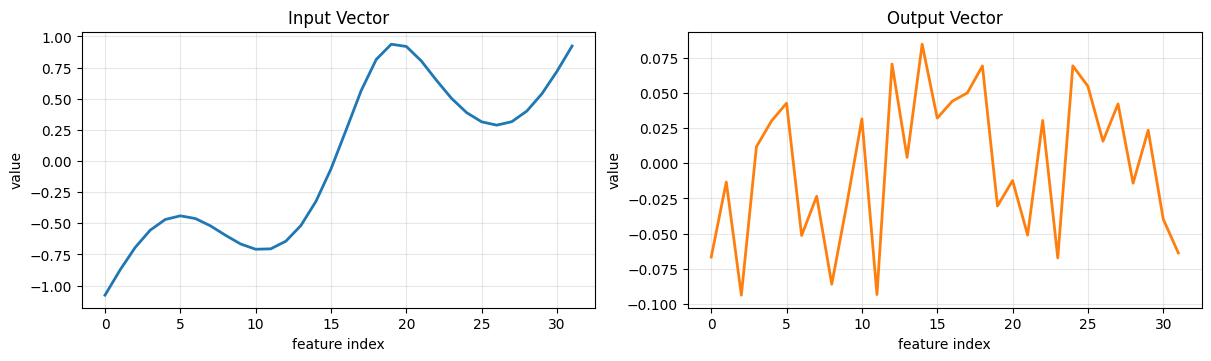

In [15]:
mlp = models["mlp"]
mlp_z, mlp_t = inputs["mlp"]
mlp_y, mlp_trace = run_with_trace(mlp, mlp_z, mlp_t)

print(mlp)
display(parameter_overview(mlp))
display(parameter_groups(mlp, depth=1))
display(parameter_table(mlp))
display(stats_table([("input", mlp_z), ("output", mlp_y)]))
display(mlp_trace)

plot_vector_io(mlp_z, mlp_y);

## 4. Bonnaire-style UNet deep dive

For the UNet the main questions are different:
- does the wrapper really hold the Bonnaire-style implementation?
- how much of the parameter budget lives in the encoder/decoder trunk?
- do the spatial sizes and channel counts behave as expected across the forward pass?

The image shown below is a synthetic grayscale pattern. The output is still untrained, so we care about **contract sanity**, not semantic quality.

BonnaireUNet(
  (model): SmallUNet(
    (time_embed): TimeMLPEmbedding(
      (sinusoidal): SinusoidalTimeEmbedding()
      (mlp): Sequential(
        (0): Linear(in_features=256, out_features=1024, bias=True)
        (1): SiLU()
        (2): Linear(in_features=1024, out_features=256, bias=True)
      )
    )
    (input_conv): Conv2d(1, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (encoder_blocks): ModuleList(
      (0): ModuleList(
        (0-1): 2 x ResBlock(
          (norm1): GroupNorm(32, 64, eps=1e-05, affine=True)
          (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
          (time_proj): Linear(in_features=256, out_features=128, bias=True)
          (norm2): GroupNorm(32, 64, eps=1e-05, affine=True)
          (dropout): Identity()
          (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
          (skip): Identity()
        )
      )
      (1): ModuleList(
        (0): ResBlock(
          (norm1): GroupNor

,metric,count,pretty
0,total_params,25810369,25.81M
1,trainable_params,25810369,25.81M
2,frozen_params,0,0


,group,params,pretty
0,model.decoder_blocks,14084800,14.08M
1,model.encoder_blocks,5860352,5.86M
2,model.decoder_upsamples,1327744,1.33M
3,model.middle_block1,1312768,1.31M
4,model.middle_block2,1312768,1.31M
5,model.encoder_downsamples,774592,774.59K
6,model.time_embed,525568,525.57K
7,model.encoder_attns,346752,346.75K
8,model.middle_attn,263680,263.68K
9,model.input_conv,640,640


,name,shape,params,pretty,trainable
0,model.decoder_blocks.1.0.conv1.weight,"(256, 512, 3, 3)",1179648,1.18M,True
1,model.decoder_blocks.1.1.conv1.weight,"(256, 512, 3, 3)",1179648,1.18M,True
2,model.decoder_blocks.0.0.conv1.weight,"(256, 512, 3, 3)",1179648,1.18M,True
3,model.decoder_blocks.0.2.conv1.weight,"(256, 512, 3, 3)",1179648,1.18M,True
4,model.decoder_blocks.0.1.conv1.weight,"(256, 512, 3, 3)",1179648,1.18M,True
5,model.decoder_blocks.1.2.conv1.weight,"(256, 384, 3, 3)",884736,884.74K,True
6,model.encoder_blocks.2.0.conv2.weight,"(256, 256, 3, 3)",589824,589.82K,True
7,model.middle_block2.conv1.weight,"(256, 256, 3, 3)",589824,589.82K,True
8,model.decoder_blocks.0.0.conv2.weight,"(256, 256, 3, 3)",589824,589.82K,True
9,model.encoder_blocks.2.1.conv1.weight,"(256, 256, 3, 3)",589824,589.82K,True


,name,shape,mean,std,min,max,l2_norm
0,input,"(1, 1, 32, 32)",0.1261,0.243011,-0.299615,0.819008,8.760977
1,output,"(1, 1, 32, 32)",0.0000,0.000000,0.000000,0.000000,0.000000


,module,class,input_shape,output_shape,direct_params,pretty
0,model.time_embed.mlp.0,Linear,"[(1, 256)]","(1, 1024)",263168,263.17K
1,model.time_embed.mlp.2,Linear,"[(1, 1024)]","(1, 256)",262400,262.40K
2,model.input_conv,Conv2d,"[(1, 1, 32, 32)]","(1, 64, 32, 32)",640,640
3,model.encoder_blocks.0.0.norm1,GroupNorm,"[(1, 64, 32, 32)]","(1, 64, 32, 32)",128,128
4,model.encoder_blocks.0.0.conv1,Conv2d,"[(1, 64, 32, 32)]","(1, 64, 32, 32)",36928,36.93K
5,model.encoder_blocks.0.0.time_proj,Linear,"[(1, 256)]","(1, 128)",32896,32.90K
6,model.encoder_blocks.0.0.norm2,GroupNorm,"[(1, 64, 32, 32)]","(1, 64, 32, 32)",128,128
7,model.encoder_blocks.0.0.conv2,Conv2d,"[(1, 64, 32, 32)]","(1, 64, 32, 32)",36928,36.93K
8,model.encoder_blocks.0.1.norm1,GroupNorm,"[(1, 64, 32, 32)]","(1, 64, 32, 32)",128,128
9,model.encoder_blocks.0.1.conv1,Conv2d,"[(1, 64, 32, 32)]","(1, 64, 32, 32)",36928,36.93K


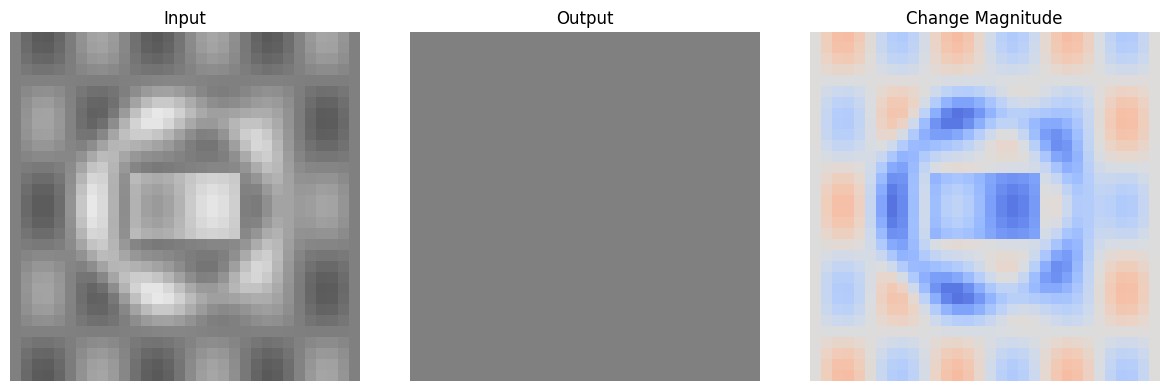

In [17]:
unet = models["unet"]
unet_z, unet_t = inputs["unet"]
unet_y, unet_trace = run_with_trace(unet, unet_z, unet_t)

print(unet)
display(parameter_overview(unet))
display(parameter_groups(unet, depth=2).head(20))
display(parameter_table(unet).head(20))
display(stats_table([("input", unet_z), ("output", unet_y)]))
display(unet_trace)

plot_image_io(unet_z, unet_y);

## 5. JiT deep dive

The JiT wrapper is the most important setup sanity check because it is not a home-grown scaffold anymore: it wraps the vendored Li & He implementation and hides the dummy unconditional label handling inside the wrapper.

Besides the usual parameter and trace tables, we also inspect a few patch-level quantities:
- `patch_size`
- `patch_dim`
- `seq_length`
- `bottleneck_ratio`

JiT(
  (model): JiT(
    (t_embedder): TimestepEmbedder(
      (mlp): Sequential(
        (0): Linear(in_features=256, out_features=768, bias=True)
        (1): SiLU()
        (2): Linear(in_features=768, out_features=768, bias=True)
      )
    )
    (y_embedder): LabelEmbedder(
      (embedding_table): Embedding(2, 768)
    )
    (x_embedder): BottleneckPatchEmbed(
      (proj1): Conv2d(3, 128, kernel_size=(16, 16), stride=(16, 16), bias=False)
      (proj2): Conv2d(128, 768, kernel_size=(1, 1), stride=(1, 1))
    )
    (feat_rope): DeviceSafeVisionRotaryEmbeddingFast()
    (feat_rope_incontext): DeviceSafeVisionRotaryEmbeddingFast()
    (blocks): ModuleList(
      (0-11): 12 x JiTBlock(
        (norm1): RMSNorm()
        (attn): Attention(
          (q_norm): RMSNorm()
          (k_norm): RMSNorm()
          (qkv): Linear(in_features=768, out_features=2304, bias=True)
          (attn_drop): Dropout(p=0.0, inplace=False)
          (proj): Linear(in_features=768, out_features=768, bia

,image_size,image_channels,patch_size,patch_dim,seq_length,hidden_dim,depth,heads,bottleneck_dim,bottleneck_ratio
0,64,3,16,768,16,768,12,12,128,1.0


,metric,count,pretty
0,total_params,130368768,130.37M
1,trainable_params,130356480,130.36M
2,frozen_params,12288,12.29K


,group,params,pretty
0,model.blocks,127572480,127.57M
1,model.final_layer,1772544,1.77M
2,model.t_embedder,787968,787.97K
3,model.x_embedder,197376,197.38K
4,model.in_context_posemb,24576,24.58K
5,model.pos_embed,12288,12.29K
6,model.y_embedder,1536,1.54K


,name,shape,params,pretty,trainable
0,model.blocks.5.adaLN_modulation.1.weight,"(4608, 768)",3538944,3.54M,True
1,model.blocks.3.adaLN_modulation.1.weight,"(4608, 768)",3538944,3.54M,True
2,model.blocks.8.adaLN_modulation.1.weight,"(4608, 768)",3538944,3.54M,True
3,model.blocks.10.adaLN_modulation.1.weight,"(4608, 768)",3538944,3.54M,True
4,model.blocks.2.adaLN_modulation.1.weight,"(4608, 768)",3538944,3.54M,True
5,model.blocks.4.adaLN_modulation.1.weight,"(4608, 768)",3538944,3.54M,True
6,model.blocks.7.adaLN_modulation.1.weight,"(4608, 768)",3538944,3.54M,True
7,model.blocks.11.adaLN_modulation.1.weight,"(4608, 768)",3538944,3.54M,True
8,model.blocks.0.adaLN_modulation.1.weight,"(4608, 768)",3538944,3.54M,True
9,model.blocks.6.adaLN_modulation.1.weight,"(4608, 768)",3538944,3.54M,True


,name,shape,mean,std,min,max,l2_norm
0,input,"(1, 3, 64, 64)",0.045363,0.406695,-1.0,1.0,45.362244
1,output,"(1, 3, 64, 64)",0.000000,0.000000,0.0,0.0,0.000000


JiT trace length: 113 rows


,module,class,input_shape,output_shape,direct_params,pretty
0,model.t_embedder.mlp.0,Linear,"[(1, 256)]","(1, 768)",197376,197.38K
1,model.t_embedder.mlp.2,Linear,"[(1, 768)]","(1, 768)",590592,590.59K
2,model.y_embedder.embedding_table,Embedding,"[(1,)]","(1, 768)",1536,1.54K
3,model.x_embedder.proj1,Conv2d,"[(1, 3, 64, 64)]","(1, 128, 4, 4)",98304,98.30K
4,model.x_embedder.proj2,Conv2d,"[(1, 128, 4, 4)]","(1, 768, 4, 4)",99072,99.07K
5,model.blocks.0.adaLN_modulation.1,Linear,"[(1, 768)]","(1, 4608)",3543552,3.54M
6,model.blocks.0.norm1,RMSNorm,"[(1, 16, 768)]","(1, 16, 768)",768,768
7,model.blocks.0.attn.qkv,Linear,"[(1, 16, 768)]","(1, 16, 2304)",1771776,1.77M
8,model.blocks.0.attn.q_norm,RMSNorm,"[(1, 12, 16, 64)]","(1, 12, 16, 64)",64,64
9,model.blocks.0.attn.k_norm,RMSNorm,"[(1, 12, 16, 64)]","(1, 12, 16, 64)",64,64


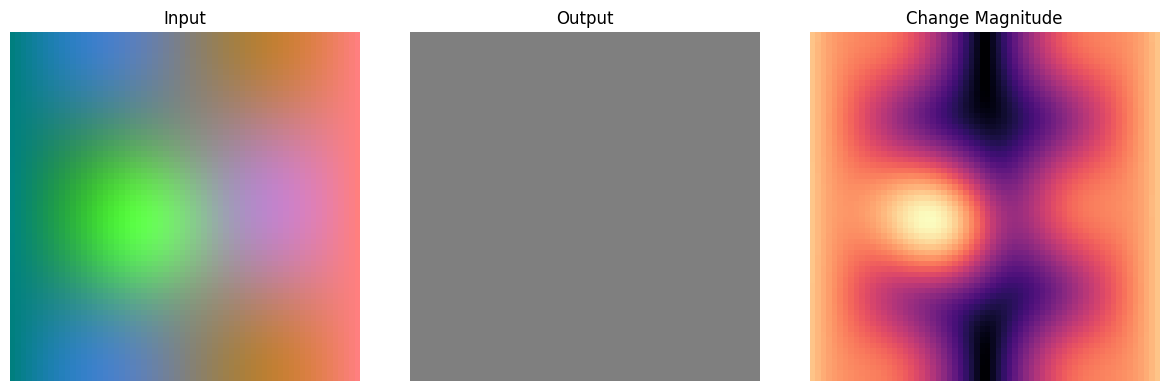

In [18]:
jit = models["jit"]
jit_z, jit_t = inputs["jit"]
jit_y, jit_trace = run_with_trace(jit, jit_z, jit_t)

print(jit)
display(
    pd.DataFrame(
        [
            {
                "image_size": jit.image_size,
                "image_channels": jit.image_channels,
                "patch_size": jit.patch_size,
                "patch_dim": jit.patch_dim,
                "seq_length": jit.seq_length,
                "hidden_dim": jit.hidden_dim,
                "depth": jit.depth,
                "heads": jit.heads,
                "bottleneck_dim": jit.bottleneck_dim,
                "bottleneck_ratio": round(jit.bottleneck_ratio, 3),
            }
        ]
    )
)
display(parameter_overview(jit))
display(parameter_groups(jit, depth=2).head(25))
display(parameter_table(jit).head(25))
display(stats_table([("input", jit_z), ("output", jit_y)]))
print(f"JiT trace length: {len(jit_trace)} rows")
display(jit_trace.head(60))

plot_image_io(jit_z, jit_y);

## 6. Cross-backbone summary

At this point we can compare the three backbones from the same factory entrypoint.

In [19]:
comparison = pd.DataFrame(
    [
        backbone_row("mlp", mlp, mlp_z, mlp_y),
        backbone_row("unet", unet, unet_z, unet_y),
        backbone_row("jit", jit, jit_z, jit_y),
    ]
).sort_values("params")

display(comparison)

,backbone,class,inner_impl,input_shape,output_shape,params,pretty
0,mlp,TimeCondMLP,NoneType,"(1, 32)","(1, 32)",57888,57.89K
1,unet,BonnaireUNet,SmallUNet,"(1, 1, 32, 32)","(1, 1, 32, 32)",25810369,25.81M
2,jit,JiT,JiT,"(1, 3, 64, 64)","(1, 3, 64, 64)",130368768,130.37M


In [20]:
assert tuple(mlp_y.shape) == tuple(mlp_z.shape)
assert tuple(unet_y.shape) == tuple(unet_z.shape)
assert tuple(jit_y.shape) == tuple(jit_z.shape)
assert (
    factory_table.loc[factory_table.backbone == "mlp", "wrapper_class"].item()
    == "TimeCondMLP"
)
assert (
    factory_table.loc[factory_table.backbone == "unet", "wrapper_class"].item()
    == "BonnaireUNet"
)
assert (
    factory_table.loc[factory_table.backbone == "jit", "wrapper_class"].item() == "JiT"
)

"All model-setup sanity checks passed."

'All model-setup sanity checks passed.'

## Takeaway

This notebook should leave us with a concrete mental model of the current `gdfm` setup layer:
- the **factory surface** is the nested `cfg.network` / `cfg.data` API
- the **MLP** is the canonical flat-vector backbone for synthetic work
- the **UNet** wrapper really points at the Bonnaire-style image backbone already used elsewhere in the repo
- the **JiT** wrapper really points at the vendored Li & He implementation, with unconditional dummy-label handling hidden inside the wrapper
- all three backbones satisfy their expected input/output contracts on real forward passes

From here, the next refactors can focus on experiment wiring or GDFM integration without having to guess whether model setup itself is behaving.

## 7. Use The Components Yourself

The sections above were written as a walkthrough. The cells below are meant to be **yours**.

They follow one simple pattern:
1. define a nested config
2. build the network with `build_network(cfg)`
3. prepare one input tensor `z` and one time batch `t`
4. run a forward pass
5. inspect parameter counts, shape traces, and the input/output visualization

If you only want one thing from this notebook for day-to-day use, it is the helper in the next cell.

In [ ]:
def try_backbone(name, cfg, z, t, group_depth=2, trace_rows=25, param_rows=15):
    """
    Build a backbone from `cfg`, run one forward pass, and display the most
    useful sanity-check views in one place.

    This is intentionally notebook-facing and opinionated. It is here so you
    can edit a config, rerun one cell, and immediately see whether the network
    still looks like what you think it is.
    """
    model = build_network(cfg).to(DEVICE)
    z = z.to(DEVICE)
    t = t.to(DEVICE)
    y, trace = run_with_trace(model, z, t)

    print(f"===== {name} =====")
    print(model)
    display(pd.DataFrame([_normalize_network_config(cfg)]))
    display(parameter_overview(model))
    display(parameter_groups(model, depth=group_depth).head(param_rows))
    display(stats_table([("input", z), ("output", y)]))
    display(trace.head(trace_rows))

    if z.dim() == 2:
        plot_vector_io(z, y)
    elif z.dim() == 4:
        plot_image_io(z, y)
    else:
        print("No visualization rule for input rank", z.dim())

    return model, y, trace

### Minimal copy-paste recipe

This is the smallest useful pattern. Start here, then adapt one of the three concrete examples below.

In [ ]:
example_cfg = ConfigDict()
example_cfg.network = ConfigDict()
example_cfg.network.arch = "mlp"
example_cfg.network.hidden_dim = 96
example_cfg.network.n_layers = 3
example_cfg.network.time_emb_dim = 64

example_cfg.data = ConfigDict()
example_cfg.data.data_dim = 24

example_z = make_vector_demo(example_cfg.data.data_dim, batch_size=1)
example_t = make_time_batch(1, value=0.20)

example_model, example_y, example_trace = try_backbone(
    "minimal example",
    example_cfg,
    example_z,
    example_t,
)

### Edit-Me Example: MLP

This is the cleanest place to experiment with hidden width, depth, and time embedding size for synthetic work.

In [ ]:
my_mlp_cfg = ConfigDict()
my_mlp_cfg.network = ConfigDict()
my_mlp_cfg.network.arch = "mlp"
my_mlp_cfg.network.hidden_dim = 128
my_mlp_cfg.network.n_layers = 4
my_mlp_cfg.network.time_emb_dim = 64

my_mlp_cfg.data = ConfigDict()
my_mlp_cfg.data.data_dim = 32

my_mlp_z = make_vector_demo(my_mlp_cfg.data.data_dim, batch_size=1)
my_mlp_t = make_time_batch(1, value=0.35)

my_mlp_model, my_mlp_y, my_mlp_trace = try_backbone(
    "my mlp",
    my_mlp_cfg,
    my_mlp_z,
    my_mlp_t,
    group_depth=1,
)

### Edit-Me Example: UNet

This is the direct pattern for a Bonnaire-style image backbone. The easiest knobs to change are:
- `base_channels`
- `channel_mult`
- `attn_resolutions`
- `num_res_blocks`
- `image_channels` and `image_size`

In [ ]:
my_unet_cfg = ConfigDict()
my_unet_cfg.network = ConfigDict()
my_unet_cfg.network.arch = "unet"
my_unet_cfg.network.base_channels = 64
my_unet_cfg.network.channel_mult = (1, 2, 4, 4)
my_unet_cfg.network.attn_resolutions = (8,)
my_unet_cfg.network.num_res_blocks = 2
my_unet_cfg.network.dropout = 0.0
my_unet_cfg.network.time_emb_dim = 256

my_unet_cfg.data = ConfigDict()
my_unet_cfg.data.image_size = 32
my_unet_cfg.data.image_channels = 1

my_unet_z = make_grayscale_demo(my_unet_cfg.data.image_size, batch_size=1)
my_unet_t = make_time_batch(1, value=0.35)

my_unet_model, my_unet_y, my_unet_trace = try_backbone(
    "my unet",
    my_unet_cfg,
    my_unet_z,
    my_unet_t,
    group_depth=2,
)

### Edit-Me Example: JiT

This is the direct pattern for the vendored Li & He JiT wrapper. The geometry checks matter here, so if you change `patch_size`, make sure it still divides `image_size`.

In [ ]:
my_jit_cfg = ConfigDict()
my_jit_cfg.network = ConfigDict()
my_jit_cfg.network.arch = "jit"
my_jit_cfg.network.patch_size = 16
my_jit_cfg.network.hidden_dim = 768
my_jit_cfg.network.depth = 12
my_jit_cfg.network.heads = 12
my_jit_cfg.network.bottleneck_dim = 128
my_jit_cfg.network.proj_dropout = 0.0
my_jit_cfg.network.attn_dropout = 0.0
my_jit_cfg.network.in_context_len = 32
my_jit_cfg.network.in_context_start = 4

my_jit_cfg.data = ConfigDict()
my_jit_cfg.data.image_size = 64
my_jit_cfg.data.image_channels = 3

my_jit_z = make_rgb_demo(my_jit_cfg.data.image_size, batch_size=1)
my_jit_t = make_time_batch(1, value=0.35)

my_jit_model, my_jit_y, my_jit_trace = try_backbone(
    "my jit",
    my_jit_cfg,
    my_jit_z,
    my_jit_t,
    group_depth=2,
    trace_rows=40,
)

### A good workflow when you edit these cells

- Change **one** structural knob at a time.
- Rerun the cell and check the normalized config table first.
- Then check the parameter overview and grouped parameter table.
- Then look at the trace rows to confirm the layer geometry is what you meant.
- Use the visualization last, as a contract check rather than a quality check.

For this notebook, the outputs are untrained by design. If the shapes, parameter budgets, and wrapper/inner-model story all look right, then the setup layer is doing its job.